# Segmentación conductual de tarjetas de crédito

**La pregunta de negocio.** Un banco quiere adaptar sus acciones comerciales al comportamiento de sus clientes de tarjeta. ¿Qué grupos existen, son estables y justifican acciones distintas?


## Guía de lectura

**Qué vas a aprender**

- Por qué en segmentación no existe una respuesta "correcta" y cómo decidir de todos modos.
- A elegir el número de grupos con varios criterios, y no solo con una métrica.
- A comprobar si los grupos son estables y si superan a datos sin estructura.
- A retar un modelo con una regla simple.
- A traducir segmentos en reglas operativas y en un piloto medible.

**Mapa del notebook**

| Sección | Pregunta que responde |
|---|---|
| 1. Problema y configuración | ¿Qué decidimos y con qué reglas? |
| 2. Calidad de datos | ¿Podemos confiar en el archivo? |
| 3. Variables y partición | ¿Qué información usamos y cómo evitamos engañarnos? |
| 4. Búsqueda de segmentos | ¿Cuántos grupos y con qué método? |
| 5. Prueba final | ¿Se sostiene en clientes nuevos? |
| 6. Perfiles | ¿Quiénes son? |
| 7. Validación y sensibilidad | ¿Qué tan frágil es el resultado? |
| 8. Uso en la gestión | ¿Cómo se opera y cómo se mide? |
| 9. Ficha del modelo | ¿Cómo se documenta? |
| 10. Limitaciones y monitoreo | ¿Qué no sabemos? |
| Conclusión | ¿Qué recomendamos? |

### Glosario rápido

| Término | Significado |
|---|---|
| **Segmento o clúster** | Grupo de clientes con comportamiento parecido |
| **`k`** | Número de segmentos |
| **Centroide** | Cliente promedio de un segmento |
| **Silhouette** | Compara qué tan cerca está un cliente de su grupo y del grupo vecino |
| **Eta² (η²)** | Parte de la variación de una medida que explican los segmentos |
| **ARI** | Coincidencia entre dos segmentaciones, descontando el azar; 1 es idéntica y 0 equivale al azar |
| **Datos sin estructura** | Datos con cada columna barajada por separado, para que no exista relación entre variables |
| **Fidelidad** | Porcentaje de clientes que las reglas asignan igual que el modelo |

## 1. Definición del problema y configuración

| Elemento | Definición |
|---|---|
| **Producto** | Tarjeta de crédito |
| **Unidad de análisis** | Un cliente |
| **Tipo de problema** | Segmentación no supervisada |
| **Uso previsto** | Diseñar acciones comerciales distintas y probarlas en un piloto |
| **Fuera de alcance** | Aprobar crédito, fijar límites o decidir tasas |

**Datos.** *Credit Card Dataset for Clustering* de Kaggle. Resume el comportamiento de unos 9,000 titulares activos, con una fila por cliente.

**La dificultad central.** Aquí no hay una respuesta correcta contra la cual medir. Un buen segmento debe ser **distinguible, estable, de tamaño útil y accionable**, y cada criterio se revisa por separado.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import HDBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.max_rows', 120, 'display.width', 200)

### Los parámetros del estudio

| Parámetro | Valor | Qué significa y por qué |
|---|---|---|
| `SEMILLA` | 51 | Fija el azar para repetir los resultados |
| `PROP_TRAIN`, `PROP_VALID` | 60 % y 20 % | Entrenar, elegir y probar con clientes distintos; el 20 % restante es la prueba final |
| `RANGO_K` | 2 a 8 | Valores de `k` evaluados |
| `K_MINIMO` | 3 | Requisito de negocio: se necesitan al menos 3 acciones distintas |
| `TAMANO_MINIMO` | 8 % | Un grupo más pequeño difícilmente justifica una campaña propia |
| `ESTABILIDAD_MINIMA` | 0.80 | El percentil 10 del ARI debe superar este valor; es exigente, porque mira los peores casos |
| `GANANCIA_MINIMA` | 0.03 | Un grupo adicional debe sumar al menos 3 puntos de eta² |
| `TOLERANCIA_ETA` | 0.02 | Entre opciones a menos de 0.02, se prefiere la más simple |
| `RESPUESTA_BASE` | 5 % | Valor ilustrativo para dimensionar un piloto |

> **Criterio.** Estos umbrales son decisiones de diseño. Son razonables, pero no son leyes: cambiarlos puede cambiar la elección.

In [2]:
# Partición de clientes
SEMILLA = 51
PROP_TRAIN, PROP_VALID = 0.60, 0.20

# Búsqueda de segmentos
RANGO_K = range(2, 9)
K_MINIMO = 3                 # se necesitan al menos 3 acciones comerciales distintas
TAMANO_MINIMO = 0.08         # ningún segmento puede tener menos de 8 % de los clientes
ESTABILIDAD_MINIMA = 0.80    # percentil 10 del ARI entre reentrenamientos
GANANCIA_MINIMA = 0.03       # aumento de eta cuadrado que justifica un segmento adicional
TOLERANCIA_ETA = 0.02        # diferencia por debajo de la cual preferimos lo más simple

# Remuestreos
N_ESTABILIDAD, N_ESTABILIDAD_WARD, N_NULO, N_BOOTSTRAP = 20, 8, 5, 1000

# Piloto comercial (valores ilustrativos)
RESPUESTA_BASE, Z_ALFA, Z_POTENCIA = 0.05, 1.96, 0.84

AZUL, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})

def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

## 2. Calidad de datos

No basta con contar nulos: hay que preguntarse **por qué falta un dato**. Un cliente sin pagos no tiene un pago mínimo registrado, y eso no es lo mismo que un error. Por eso cada control lleva su tratamiento.

In [3]:
candidatas = [Path('data/CC GENERAL.csv'), Path('CC GENERAL.csv'), Path.home() / 'Downloads' / 'CC GENERAL.csv']
ruta = next(p for p in candidatas if p.is_file())
crudo = pd.read_csv(ruta)
assert crudo.shape == (8950, 18), 'El archivo no coincide con la versión esperada'
assert crudo['CUST_ID'].is_unique

faltantes = crudo.isna().sum()[lambda s: s > 0].rename('faltantes').to_frame()
faltantes['%'] = (faltantes['faltantes'] / len(crudo) * 100).round(2)
print(f'Clientes: {len(crudo):,} | Columnas: {crudo.shape[1]} | Duplicados: {int(crudo.duplicated().sum())}')
display(faltantes)
controles = pd.DataFrame([
    ('MINIMUM_PAYMENTS faltante y sin pagos', int((crudo['MINIMUM_PAYMENTS'].isna() & (crudo['PAYMENTS'] == 0)).sum()), 'Faltante estructural: no hubo pagos'),
    ('MINIMUM_PAYMENTS faltante con pagos', int((crudo['MINIMUM_PAYMENTS'].isna() & (crudo['PAYMENTS'] > 0)).sum()), 'Imputar con mediana de entrenamiento'),
    ('CREDIT_LIMIT faltante', int(crudo['CREDIT_LIMIT'].isna().sum()), 'Imputar con mediana de entrenamiento'),
    ('CASH_ADVANCE_FREQUENCY mayor que 1', int((crudo['CASH_ADVANCE_FREQUENCY'] > 1).sum()), 'Inválido: limitar a 1'),
    ('PURCHASES difiere de ONEOFF + INSTALLMENTS', int(((crudo['PURCHASES'] - crudo['ONEOFF_PURCHASES'] - crudo['INSTALLMENTS_PURCHASES']).abs() > 1).sum()), 'Se conserva y se documenta'),
    ('BALANCE mayor que CREDIT_LIMIT', int((crudo['BALANCE'] > crudo['CREDIT_LIMIT']).sum()), 'Se conserva: sobregiro posible'),
    ('TENURE distinto de 12 meses', int((crudo['TENURE'] != 12).sum()), 'Se revisa en sensibilidad'),
], columns=['Control', 'Casos', 'Tratamiento']).set_index('Control')
display(controles)
crudo.describe(percentiles=[.5, .95, .99]).T.round(2)

Clientes: 8,950 | Columnas: 18 | Duplicados: 0


,faltantes,%
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


,Casos,Tratamiento
Control,,
MINIMUM_PAYMENTS faltante y sin pagos,240,Faltante estructural: no hubo pagos
MINIMUM_PAYMENTS faltante con pagos,73,Imputar con mediana de entrenamiento
CREDIT_LIMIT faltante,1,Imputar con mediana de entrenamiento
CASH_ADVANCE_FREQUENCY mayor que 1,8,Inválido: limitar a 1
PURCHASES difiere de ONEOFF + INSTALLMENTS,19,Se conserva y se documenta
BALANCE mayor que CREDIT_LIMIT,227,Se conserva: sobregiro posible
TENURE distinto de 12 meses,1366,Se revisa en sensibilidad


,count,mean,std,min,50%,95%,99%,max
BALANCE,8950.0,1564.47,2081.53,0.00,873.39,5909.11,9338.80,19043.14
BALANCE_FREQUENCY,8950.0,0.88,0.24,0.00,1.00,1.00,1.00,1.00
PURCHASES,8950.0,1003.20,2136.63,0.00,361.28,3998.62,8977.29,49039.57
ONEOFF_PURCHASES,8950.0,592.44,1659.89,0.00,38.00,2671.09,6689.90,40761.25
INSTALLMENTS_PURCHASES,8950.0,411.07,904.34,0.00,89.00,1750.09,3886.24,22500.00
CASH_ADVANCE,8950.0,978.87,2097.16,0.00,0.00,4647.17,9588.16,47137.21
PURCHASES_FREQUENCY,8950.0,0.49,0.40,0.00,0.50,1.00,1.00,1.00
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.20,0.30,0.00,0.08,1.00,1.00,1.00
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.36,0.40,0.00,0.17,1.00,1.00,1.00
CASH_ADVANCE_FREQUENCY,8950.0,0.14,0.20,0.00,0.00,0.58,0.83,1.50


**Lectura.**

- **Faltantes.** `MINIMUM_PAYMENTS` tiene 313 faltantes, y 240 corresponden a clientes sin pagos.
- **Valor imposible.** Una frecuencia es una proporción, así que no puede superar 1. Ocho clientes la superan en `CASH_ADVANCE_FREQUENCY` y se limitan a 1.
- **Sobregiro.** 227 clientes tienen saldo mayor que su límite. Es posible en una tarjeta si `BALANCE` representa deuda, un supuesto que explicamos en el diccionario de la sección 9. Por eso se conserva.
- **Antigüedad.** 1,366 clientes tienen menos de 12 meses. La descripción del archivo habla de los últimos 6 meses, mientras `TENURE` llega a 12, una ambigüedad que revisamos en la sección 7.
- **Distribuciones muy asimétricas.** El máximo de `PURCHASES` es 49,040 y la mediana 361. Sin transformar, unos pocos clientes dominarían el análisis.

## 3. Variables y partición

**Partición.** Separamos a los clientes en tres grupos: entrenamiento para formar segmentos, validación para elegir la configuración y prueba para el examen final. Como el archivo no tiene fechas, la separación es aleatoria y **no permite evaluar estabilidad en el tiempo**.

**Tres conjuntos de variables compiten:**

| Base | Variables | Idea |
|---|---|---|
| **compacta** | 5 | Saldo, compras, avances, número de compras y pago total |
| **todas** | 17 | Todo el archivo, con mucha información repetida |
| **comportamiento** | 9 | Variables de negocio como utilización, cuotas y cobertura del pago mínimo |

**Preparación.** En la base compacta aplicamos `log(1 + x)` a las cinco variables para reducir la asimetría: tres montos, un conteo y una proporción. En `PRC_FULL_PAYMENT`, que va de 0 a 1, su efecto es pequeño, y se mantiene para aplicar una sola regla. Las otras bases lo aplican a sus variables más asimétricas. Luego estandarizamos: cada variable queda con media 0 y desviación 1. K-means mide distancias, así que sin esa escala las variables con números grandes dominarían. Los parámetros se aprenden **solo en entrenamiento**.

**Un patrón de medida común.** No se puede comparar la silhouette entre bases, porque cada una mide distancias en un espacio distinto. Por eso usamos **eta²**, calculada siempre sobre las mismas 8 medidas de negocio.

**Ejemplo de eta².** Cuatro clientes tienen los valores 0, 2, 10 y 12, y su media es 6. La variación total es $36 + 16 + 16 + 36 = 104$. Si formamos los grupos (0, 2) y (10, 12), la variación dentro de ellos es $1 + 1 + 1 + 1 = 4$. Entonces $\eta^2 = 1 - 4/104 = 0.96$: los grupos explican el 96 % de la variación.

In [4]:
orden = np.random.default_rng(SEMILLA).permutation(len(crudo))
c1, c2 = int(PROP_TRAIN * len(crudo)), int((PROP_TRAIN + PROP_VALID) * len(crudo))
tr, va, te = orden[:c1], orden[c1:c2], orden[c2:]

mediana_limite = crudo['CREDIT_LIMIT'].iloc[tr].median()
mediana_minimo = crudo['MINIMUM_PAYMENTS'].iloc[tr].median()

def limpiar(d):
    d = d.copy()
    d['CREDIT_LIMIT'] = d['CREDIT_LIMIT'].fillna(mediana_limite)
    d['CASH_ADVANCE_FREQUENCY'] = d['CASH_ADVANCE_FREQUENCY'].clip(0, 1)
    return d

def base_compacta(d):
    columnas = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_TRX', 'PRC_FULL_PAYMENT']
    return np.log1p(d[columnas])

def base_todas(d):
    x = d.drop(columns='CUST_ID').copy()
    x['MINIMUM_PAYMENTS'] = x['MINIMUM_PAYMENTS'].fillna(mediana_minimo)
    montos = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT',
              'PAYMENTS', 'MINIMUM_PAYMENTS', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX']
    x[montos] = np.log1p(x[montos])
    return x

def base_comportamiento(d, por_mes=True):
    meses = d['TENURE'] if por_mes else 1
    minimo = d['MINIMUM_PAYMENTS'].where(d['PAYMENTS'] > 0, 1).fillna(mediana_minimo)
    return pd.DataFrame({
        'log_limite': np.log1p(d['CREDIT_LIMIT']),
        'utilizacion': (d['BALANCE'] / d['CREDIT_LIMIT']).clip(0, 1.5),
        'log_compra_mes': np.log1p(d['PURCHASES'] / meses),
        'log_avance_mes': np.log1p(d['CASH_ADVANCE'] / meses),
        'frec_compra': d['PURCHASES_FREQUENCY'],
        'frec_avance': d['CASH_ADVANCE_FREQUENCY'],
        'pct_cuotas': (d['INSTALLMENTS_PURCHASES'] / d['PURCHASES'].replace(0, np.nan)).fillna(0).clip(0, 1),
        'pago_total': d['PRC_FULL_PAYMENT'],
        'log_cobertura': np.log1p((d['PAYMENTS'] / minimo).clip(0, 20)),
    }, index=d.index)

df = limpiar(crudo)
BASES = {'compacta': base_compacta(df), 'todas': base_todas(df), 'comportamiento': base_comportamiento(df)}
MATRICES = {n: StandardScaler().fit(b.iloc[tr]).transform(b) for n, b in BASES.items()}

# Resultados de negocio: el mismo patrón de medida para todas las alternativas
COLS_RESULTADO = ['log_limite', 'utilizacion', 'log_compra_mes', 'log_avance_mes', 'frec_compra', 'frec_avance', 'pago_total', 'log_cobertura']
RESULTADO = StandardScaler().fit(BASES['comportamiento'][COLS_RESULTADO].iloc[tr]).transform(BASES['comportamiento'][COLS_RESULTADO])

def eta2(g, idx, Y=RESULTADO):
    y_ = Y[idx]
    total = ((y_ - y_.mean(0)) ** 2).sum()
    dentro = sum(((y_[g == j] - y_[g == j].mean(0)) ** 2).sum() for j in np.unique(g))
    return 1 - dentro / total

print(f'Entrenamiento: {len(tr):,} | Validación: {len(va):,} | Prueba: {len(te):,}')
pd.DataFrame({'Variables': {n: b.shape[1] for n, b in BASES.items()}})

Entrenamiento: 5,370 | Validación: 1,790 | Prueba: 1,790


,Variables
compacta,5
todas,17
comportamiento,9


**Lectura.** Con 5,370 clientes para entrenar y 1,790 para validar y para probar, hay suficientes datos para medir la estabilidad. Fíjate en que la base **todas** repite información: por ejemplo, `PURCHASES` y `ONEOFF_PURCHASES` tienen una correlación de 0.92, de modo que ese comportamiento pesa más en las distancias.

## 4. Búsqueda de segmentos

**Algoritmos**

| Algoritmo | Idea | Forma de los grupos |
|---|---|---|
| **K-means** | Alterna entre asignar cada cliente al centro más cercano y recalcular los centros | Compactos y parecidos en tamaño |
| **Ward** | Une paso a paso los grupos que menos aumentan la variación interna | Parecida a k-means, pero jerárquica |
| **Mezcla gaussiana** | Supone que cada grupo sigue una distribución normal | Más flexible, con probabilidades de pertenencia |

**Qué mide cada columna**

- **`silhouette`:** para un cliente, si $a$ es su distancia media a su grupo y $b$ al grupo vecino, vale $(b-a)/\max(a,b)$. Con $a=2$ y $b=10$ da 0.8. Cerca de 1 es mejor.
- **`silhouette_nula`:** la misma medida sobre datos sin estructura. Muestra cuánto se obtiene **sin que exista ninguna relación** entre variables.
- **`exceso`:** la diferencia entre ambas. Si fuera cercana a 0, los segmentos serían un artefacto.
- **`grupo_minimo`:** porcentaje del segmento más pequeño.
- **`ari_medio`, `ari_p10`:** reentrenamos con remuestras y comparamos las asignaciones. El percentil 10 refleja los casos desfavorables.
- **`eta2`:** información de negocio que resumen los segmentos.

Esta celda tarda unos minutos, porque entrena cientos de modelos.

In [5]:
def ajustar(algoritmo, k, X, semilla):
    if algoritmo == 'kmeans':
        return KMeans(k, n_init=10, random_state=semilla).fit(X).cluster_centers_
    if algoritmo == 'gmm':
        return GaussianMixture(k, covariance_type='diag', n_init=3, reg_covar=1e-3, random_state=semilla).fit(X)
    g = AgglomerativeClustering(k, linkage='ward').fit_predict(X)
    return np.array([X[g == j].mean(0) for j in range(k)])

def asignar(modelo, X):
    if isinstance(modelo, np.ndarray):
        return ((X[:, None, :] - modelo[None, :, :]) ** 2).sum(2).argmin(1)
    return modelo.predict(X)

def permutar(X, rng):
    """Baraja cada columna por separado: conserva cada distribución y destruye la relación entre variables."""
    return np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])

def evaluar(nombre, algoritmo, k):
    X = MATRICES[nombre]
    Xt, Xv = X[tr], X[va]
    rng = np.random.default_rng(SEMILLA)
    g = asignar(ajustar(algoritmo, k, Xt, SEMILLA), Xv)
    if len(np.unique(g)) < 2:
        return None
    sil = silhouette_score(Xv, g)
    alg_nulo = 'kmeans' if algoritmo == 'ward' else algoritmo
    nulo = []
    for b in range(N_NULO):
        pt, pv = permutar(Xt, rng), permutar(Xv, rng)
        gp = asignar(ajustar(alg_nulo, k, pt, b), pv)
        nulo.append(silhouette_score(pv, gp) if len(np.unique(gp)) > 1 else 0.0)
    aris = []
    for b in range(N_ESTABILIDAD_WARD if algoritmo == 'ward' else N_ESTABILIDAD):
        s = rng.integers(0, len(Xt), len(Xt))
        aris.append(adjusted_rand_score(g, asignar(ajustar(algoritmo, k, Xt[s], b), Xv)))
    return {'base': nombre, 'algoritmo': algoritmo, 'k': k, 'variables': X.shape[1], 'silhouette': sil,
            'silhouette_nula': np.mean(nulo), 'exceso': sil - np.mean(nulo),
            'grupo_minimo': np.bincount(g, minlength=k).min() / len(g),
            'ari_medio': np.mean(aris), 'ari_p10': np.percentile(aris, 10), 'eta2': eta2(g, va)}

res = pd.DataFrame([r for b in BASES for a in ['kmeans', 'ward', 'gmm'] for k in RANGO_K if (r := evaluar(b, a, k))])
res.round(3).sort_values(['base', 'algoritmo', 'k']).set_index(['base', 'algoritmo', 'k'])

variables  silhouette  silhouette_nula  exceso  grupo_minimo  ari_medio  ari_p10   eta2
base           algoritmo k                                                                                         
compacta       gmm       2          5       0.371            0.170   0.201         0.218      0.957    0.985  0.200
                         3          5       0.308            0.198   0.109         0.218      0.946    0.863  0.325
                         4          5       0.370            0.167   0.203         0.218      0.904    0.776  0.447
                         5          5       0.341            0.156   0.184         0.065      0.997    0.994  0.461
                         6          5       0.276            0.145   0.131         0.054      0.896    0.824  0.479
                         7          5       0.260            0.137   0.124         0.034      0.817    0.713  0.492
                         8          5       0.230            0.117   0.113         0.026      0.833    0.700  0.509
               kmeans    2          5       0.365            0.213   0.152         0.316      0.968    0.950  0.259
                         3          5       0.378            0.239   0.139         0.261      0.978    0.964  0.356
                         4          5       0.427            0.243   0.184         0.171      0.989    0.983  0.480
                         5          5       0.440            0.246   0.194         0.147      0.984    0.978  0.508
                         6          5       0.405            0.232   0.173         0.117      0.918    0.741  0.524
                         7          5       0.376            0.245   0.130         0.109      0.920    0.788  0.536
                         8          5       0.352            0.259   0.093         0.082      0.906    0.815  0.547
               ward      2          5       0.375            0.213   0.163         0.264      0.993    0.990  0.234
                         3          5       0.381            0.239   0.142         0.195      0.782    0.378  0.369
                         4          5       0.427            0.243   0.185         0.176      0.940    0.902  0.479
                         5          5       0.439            0.246   0.193         0.141      0.915    0.886  0.506
                         6          5       0.400            0.232   0.168         0.106      0.758    0.693  0.520
                         7          5       0.378            0.245   0.133         0.085      0.769    0.693  0.540
                         8          5       0.378            0.259   0.119         0.030      0.749    0.683  0.555
comportamiento gmm       2          9       0.245            0.086   0.159         0.477      1.000    1.000  0.274
                         3          9       0.201            0.059   0.143         0.215      0.893    0.763  0.355
                         4          9       0.171            0.030   0.141         0.215      0.956    0.957  0.439
                         5          9       0.164            0.029   0.135         0.082      0.962    0.878  0.465
                         6          9       0.146            0.022   0.124         0.079      0.903    0.733  0.474
                         7          9       0.127            0.025   0.102         0.058      0.895    0.816  0.486
                         8          9       0.124            0.019   0.104         0.059      0.867    0.771  0.508
               kmeans    2          9       0.269            0.106   0.163         0.423      0.968    0.949  0.290
                         3          9       0.214            0.118   0.095         0.248      0.908    0.780  0.405
                         4          9       0.230            0.111   0.119         0.161      0.952    0.895  0.489
                         5          9       0.215            0.106   0.109         0.137      0.854    0.749  0.538
                         6          9       0.223            0.104   0.119         0

**Lectura.** Mira la base **compacta** con k-means. La silhouette más alta es 0.440 con `k=5`, y solo cae un poco con `k=4`. **Por sí sola, la silhouette no decide:** puede favorecer soluciones poco útiles para el negocio y cambia con la preparación de datos.

También observa `silhouette_nula`: es 0.24, bastante alta para datos sin estructura. Muchas variables tienen muchos ceros, y eso por sí solo crea aglomeraciones. Por eso importa el exceso, y no solo la silhouette.

### La regla de decisión

Se aplica en tres pasos:

1. **Elegibilidad.** `k` de al menos 3, grupo mínimo de 8 %, percentil 10 del ARI de al menos 0.80 y exceso positivo.
2. **Número de grupos.** Partimos del mejor eta² de cada `k` y elegimos el `k` más pequeño tras el cual un grupo adicional suma menos de 0.03.
3. **Configuración.** Para ese `k`, entre las opciones a menos de 0.02 de la mejor, elegimos primero el algoritmo más simple y después la base con menos variables.

**Cómo leer el gráfico.** Cada panel usa k-means con dos bases. La línea punteada vertical marca el `k` elegido, y la horizontal el mínimo de estabilidad.

,Mejor eta² acumulado,Ganancia del siguiente k
k,,
3,0.359,0.131
4,0.489,0.019
5,0.508,0.000
6,0.508,0.040
8,0.547,NaN


k elegido: 4 | Elección final: kmeans con la base compacta


,,k,variables,eta2,ari_p10,grupo_minimo,exceso
base,algoritmo,,,,,,
compacta,kmeans,4,5,0.480,0.983,0.171,0.184
comportamiento,kmeans,4,9,0.489,0.895,0.161,0.119
compacta,ward,4,5,0.479,0.902,0.176,0.185


Cómo queda la selección por silhouette:


,silhouette,silhouette_nula,exceso,grupo_minimo,ari_p10,eta2
k,,,,,,
2,0.365,0.213,0.152,0.316,0.950,0.259
3,0.378,0.239,0.139,0.261,0.964,0.356
4,0.427,0.243,0.184,0.171,0.983,0.480
5,0.440,0.246,0.194,0.147,0.978,0.508
6,0.405,0.232,0.173,0.117,0.741,0.524
7,0.376,0.245,0.130,0.109,0.788,0.536
8,0.352,0.259,0.093,0.082,0.815,0.547


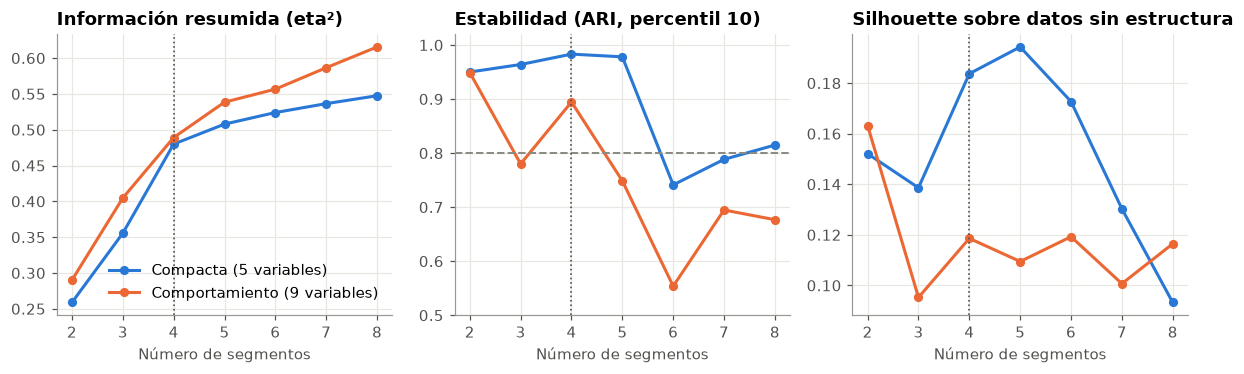

In [6]:
COMPLEJIDAD = {'kmeans': 1, 'ward': 2, 'gmm': 3}
res['elegible'] = (res['k'] >= K_MINIMO) & (res['grupo_minimo'] >= TAMANO_MINIMO) & (res['ari_p10'] >= ESTABILIDAD_MINIMA) & (res['exceso'] > 0)
elegibles = res[res['elegible']]

mejor_k = elegibles.groupby('k')['eta2'].max().cummax()
ganancia = mejor_k.diff().shift(-1)
K_ELEGIDO = int(ganancia[ganancia < GANANCIA_MINIMA].index.min()) if (ganancia < GANANCIA_MINIMA).any() else int(mejor_k.index.max())

cand = elegibles[elegibles['k'] == K_ELEGIDO].copy()
cand = cand[cand['eta2'] >= cand['eta2'].max() - TOLERANCIA_ETA]
cand['complejidad'] = cand['algoritmo'].map(COMPLEJIDAD)
cand = cand.sort_values(['complejidad', 'variables', 'eta2'], ascending=[True, True, False])
BASE, ALGORITMO = cand.iloc[0]['base'], cand.iloc[0]['algoritmo']

display(pd.DataFrame({'Mejor eta² acumulado': mejor_k.round(3), 'Ganancia del siguiente k': ganancia.round(3)}))
print(f'k elegido: {K_ELEGIDO} | Elección final: {ALGORITMO} con la base {BASE}')
display(cand[['base', 'algoritmo', 'k', 'variables', 'eta2', 'ari_p10', 'grupo_minimo', 'exceso']].round(3).set_index(['base', 'algoritmo']))

print('Cómo queda la selección por silhouette:')
display(res[res['base'] == 'compacta'].query("algoritmo == 'kmeans'")[['k', 'silhouette', 'silhouette_nula', 'exceso', 'grupo_minimo', 'ari_p10', 'eta2']].round(3).set_index('k'))

fig, ejes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True)
for base_g, color, nombre_g in [('compacta', AZUL, 'Compacta (5 variables)'), ('comportamiento', NARANJA, 'Comportamiento (9 variables)')]:
    t = res[(res['base'] == base_g) & (res['algoritmo'] == 'kmeans')]
    ejes[0].plot(t['k'], t['eta2'], color=color, marker='o', markersize=5, label=nombre_g)
    ejes[1].plot(t['k'], t['ari_p10'], color=color, marker='o', markersize=5)
    ejes[2].plot(t['k'], t['exceso'], color=color, marker='o', markersize=5)
ejes[0].set(title='Información resumida (eta²)', xlabel='Número de segmentos')
ejes[1].set(title='Estabilidad (ARI, percentil 10)', xlabel='Número de segmentos', ylim=(0.5, 1.02))
ejes[1].axhline(ESTABILIDAD_MINIMA, color=GRIS, linestyle='--', linewidth=1.3)
ejes[2].set(title='Silhouette sobre datos sin estructura', xlabel='Número de segmentos')
ejes[0].axvline(K_ELEGIDO, color=TINTA, linestyle=':', linewidth=1.1); ejes[1].axvline(K_ELEGIDO, color=TINTA, linestyle=':', linewidth=1.1); ejes[2].axvline(K_ELEGIDO, color=TINTA, linestyle=':', linewidth=1.1)
ejes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

### ¿Qué tan sensible es la elección de `k`?

Repetimos la regla de decisión con distintos valores de `GANANCIA_MINIMA`. Un umbral bajo acepta más segmentos, y uno alto prefiere menos. Si la elección cambiara con cualquier ajuste pequeño, habría que tratarla con cautela.

In [7]:
def elegir_con_umbral(umbral):
    k_u = int(ganancia[ganancia < umbral].index.min()) if (ganancia < umbral).any() else int(mejor_k.index.max())
    c_u = elegibles[elegibles['k'] == k_u]
    c_u = c_u[c_u['eta2'] >= c_u['eta2'].max() - TOLERANCIA_ETA].assign(complejidad=lambda t: t['algoritmo'].map(COMPLEJIDAD))
    f = c_u.sort_values(['complejidad', 'variables', 'eta2'], ascending=[True, True, False]).iloc[0]
    return {'k elegido': k_u, 'Configuración': f"{f['algoritmo']}, {f['base']}", 'Eta² en validación': round(f['eta2'], 3),
            'Grupo mínimo': pct(f['grupo_minimo']), 'ARI percentil 10': round(f['ari_p10'], 3)}

pd.DataFrame({u: elegir_con_umbral(u) for u in [0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.10, 0.15]}).T.rename_axis('Ganancia mínima')

,k elegido,Configuración,Eta² en validación,Grupo mínimo,ARI percentil 10
Ganancia mínima,,,,,
0.005,5,"kmeans, compacta",0.508,14.7 %,0.978
0.010,5,"kmeans, compacta",0.508,14.7 %,0.978
0.015,5,"kmeans, compacta",0.508,14.7 %,0.978
0.020,4,"kmeans, compacta",0.48,17.1 %,0.983
0.030,4,"kmeans, compacta",0.48,17.1 %,0.983
0.050,4,"kmeans, compacta",0.48,17.1 %,0.983
0.100,4,"kmeans, compacta",0.48,17.1 %,0.983
0.150,3,"kmeans, compacta",0.356,26.1 %,0.964


**Lectura.**

- De 3 a 4 grupos, el mejor eta² sube 0.131. De 4 a 5, solo 0.019. Por eso `k=4`.
- Con `k=4` quedan tres opciones dentro de la tolerancia, y gana k-means con las 5 variables de la base compacta: la más simple, y también la más estable (percentil 10 de 0.983).
- La base de comportamiento obtiene 0.489 frente a 0.480, sin compensar sus 4 variables adicionales ni su menor estabilidad.

**La lección:** cinco variables bien elegidas resumen casi lo mismo que nueve. Agregar variables no siempre justifica la complejidad adicional.

**Elegir entre 4 y 5 segmentos fue una decisión ajustada.** La tabla de sensibilidad muestra que con un umbral de 0.015 o menor se elegirían 5 grupos. Dentro de la base compacta, pasar de 4 a 5 suma 0.028, muy cerca del umbral de 0.03, y `k=5` tiene mejor silhouette (0.440) y casi la misma estabilidad (0.978). Mantenemos 4 porque cada segmento adicional exige diseñar y medir una acción distinta. Aun así, el umbral se fijó después de ver los resultados de validación, y es un juicio de negocio más que una conclusión estadística.

## 5. Prueba final

Evaluamos la elección en clientes no utilizados hasta ahora, y la comparamos con tres referencias:

- **Alterna:** k-means con la base de comportamiento.
- **Dos segmentos:** lo que se obtiene con `k=2` y las mismas variables.
- **Regla de actividad:** cuatro grupos definidos sin modelo: sin compras; con compras y avances; solo compras que pagan el total al menos la mitad de las veces; y el resto de quienes solo compran.

El bootstrap vuelve a tomar muestras de la prueba para estimar un **intervalo de confianza**. Si el intervalo de una diferencia no incluye el cero, esa diferencia es difícil de atribuir al azar.

In [8]:
X_final = MATRICES[BASE]
modelo = ajustar(ALGORITMO, K_ELEGIDO, X_final[tr], SEMILLA)
g_crudo = asignar(modelo, X_final)

perfil_tr = df.iloc[tr].groupby(g_crudo[tr])[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PRC_FULL_PAYMENT']].median()

def nombrar(p):
    """Nombra cada segmento con reglas explícitas sobre sus medianas en entrenamiento."""
    if len(p) != 4:
        return {j: f'Segmento {j + 1}' for j in p.index}
    nombres, resto = {}, list(p.index)
    a = p.loc[resto, 'PRC_FULL_PAYMENT'].idxmax(); nombres[a] = 'Pagadores totales'; resto.remove(a)
    s = p.loc[resto, 'PURCHASES'].idxmin(); nombres[s] = 'Solo avances'; resto.remove(s)
    m = p.loc[resto, 'CASH_ADVANCE'].idxmax(); nombres[m] = 'Compras y avances'; resto.remove(m)
    nombres[resto[0]] = 'Solo compras'
    return nombres

NOMBRES = nombrar(perfil_tr)
segmento = pd.Series(g_crudo, index=df.index).map(NOMBRES)
ORDEN = list(segmento.iloc[te].value_counts().index)

def regla_actividad(d):
    return np.select([d['PURCHASES'] == 0, d['CASH_ADVANCE'] > 0, d['PRC_FULL_PAYMENT'] >= 0.5], [0, 1, 2], 3)

g_regla = regla_actividad(df)
g_dos = asignar(ajustar('kmeans', 2, MATRICES['compacta'][tr], SEMILLA), MATRICES['compacta'])
alterna = 'comportamiento' if BASE != 'comportamiento' else 'compacta'
g_alterna = asignar(ajustar('kmeans', K_ELEGIDO, MATRICES[alterna][tr], SEMILLA), MATRICES[alterna])

rng = np.random.default_rng(SEMILLA)
Xte = X_final[te]
nulo_te = []
for b in range(10):
    pt, pv = permutar(X_final[tr], rng), permutar(Xte, rng)
    gp = asignar(ajustar(ALGORITMO, K_ELEGIDO, pt, b), pv)
    nulo_te.append(silhouette_score(pv, gp))

ALTERNATIVAS = {f'Elegido: {ALGORITMO}, {BASE}, k={K_ELEGIDO}': g_crudo, f'Alterna: kmeans, {alterna}, k={K_ELEGIDO}': g_alterna,
                'Dos segmentos con las mismas variables': g_dos, 'Regla de actividad': g_regla}
filas, boots = [], {}
rng = np.random.default_rng(SEMILLA)
muestras = [rng.integers(0, len(te), len(te)) for _ in range(N_BOOTSTRAP)]
for n_, g_ in ALTERNATIVAS.items():
    v = np.array([eta2(g_[te][s], te[s]) for s in muestras])
    boots[n_] = v
    filas.append({'Segmentación': n_, 'Grupos': len(np.unique(g_[te])), 'Grupo mínimo': pct(np.bincount(g_[te]).min() / len(te)),
                  'Eta²': round(eta2(g_[te], te), 3), 'IC 95 %': f'{np.percentile(v, 2.5):.3f} a {np.percentile(v, 97.5):.3f}'})
display(pd.DataFrame(filas).set_index('Segmentación'))
nom_g = list(ALTERNATIVAS)[0]
filas = []
for n_ in list(ALTERNATIVAS)[1:]:
    d_ = boots[nom_g] - boots[n_]
    filas.append({'Elegido menos': n_, 'Δ eta² medio': round(d_.mean(), 3), 'IC 95 %': f'{np.percentile(d_, 2.5):+.3f} a {np.percentile(d_, 97.5):+.3f}'})
display(pd.DataFrame(filas).set_index('Elegido menos'))
print(f'Silhouette en prueba: {silhouette_score(Xte, g_crudo[te]):.3f} | Sobre datos sin estructura: {np.mean(nulo_te):.3f}')
print(f'Coincidencia con la segmentación alterna (ARI en prueba): {adjusted_rand_score(g_crudo[te], g_alterna[te]):.3f}')
print(f'Coincidencia con la regla de actividad (ARI en prueba): {adjusted_rand_score(g_crudo[te], g_regla[te]):.3f}')

,Grupos,Grupo mínimo,Eta²,IC 95 %
Segmentación,,,,
"Elegido: kmeans, compacta, k=4",4,15.8 %,0.463,0.452 a 0.476
"Alterna: kmeans, comportamiento, k=4",4,15.6 %,0.474,0.463 a 0.488
Dos segmentos con las mismas variables,2,30.4 %,0.264,0.248 a 0.279
Regla de actividad,4,11.6 %,0.446,0.433 a 0.460


,Δ eta² medio,IC 95 %
Elegido menos,,
"Alterna: kmeans, comportamiento, k=4",-0.011,-0.015 a -0.007
Dos segmentos con las mismas variables,0.200,+0.186 a +0.214
Regla de actividad,0.017,+0.012 a +0.023


Silhouette en prueba: 0.416 | Sobre datos sin estructura: 0.252
Coincidencia con la segmentación alterna (ARI en prueba): 0.764
Coincidencia con la regla de actividad (ARI en prueba): 0.858


**Lectura.**

- **El resultado se sostiene.** El eta² es 0.463, cercano al 0.480 de validación.
- **Cuatro grupos superan ampliamente a dos,** con una diferencia de 0.200.
- **La regla simple casi empata.** La ventaja del modelo es de solo 0.017, y la coincidencia entre ambas segmentaciones es de 0.858. El modelo descubrió básicamente la misma estructura que una regla de negocio.
- **La silhouette es 0.416, frente a 0.252 sin estructura.** Hay señal real, aunque gran parte proviene de separar quién compra, quién usa avances y quién paga el total.
- **La base de comportamiento resume algo más** (0.474), y sus variables son las más parecidas a las medidas de eta². La diferencia es pequeña y usa casi el doble de variables.
- **Eta² no es una medida independiente.** Sus ocho medidas de negocio se parecen a las variables que forman los segmentos en cualquiera de las bases. Sirve para comparar alternativas, pero no prueba que los segmentos sean útiles para el negocio.

## 6. Perfiles de los segmentos

Los segmentos se nombran con reglas explícitas sobre sus medianas en entrenamiento, y sus perfiles se muestran en la prueba.

**Cómo leer el mapa de calor.** Cada celda indica cuántas desviaciones estándar se aleja el segmento del promedio. El naranja indica valores superiores y el azul, inferiores. Incluye variables que no entraron al modelo, aunque varias están muy relacionadas con las que sí entraron.

segmento,Solo compras,Compras y avances,Solo avances,Pagadores totales
BALANCE,461.46,2135.41,1428.85,68.46
PURCHASES,533.99,619.93,0.00,689.21
CASH_ADVANCE,0.00,1214.20,1196.10,0.00
PURCHASES_TRX,10.00,11.00,0.00,12.00
PRC_FULL_PAYMENT,0.00,0.00,0.00,0.75
CREDIT_LIMIT,3000.00,4500.00,3000.00,3000.00
PAYMENTS,654.51,1373.69,709.90,811.99
utilizacion,0.15,0.57,0.65,0.02
PURCHASES_FREQUENCY,0.67,0.58,0.00,0.92
CASH_ADVANCE_FREQUENCY,0.00,0.25,0.25,0.00


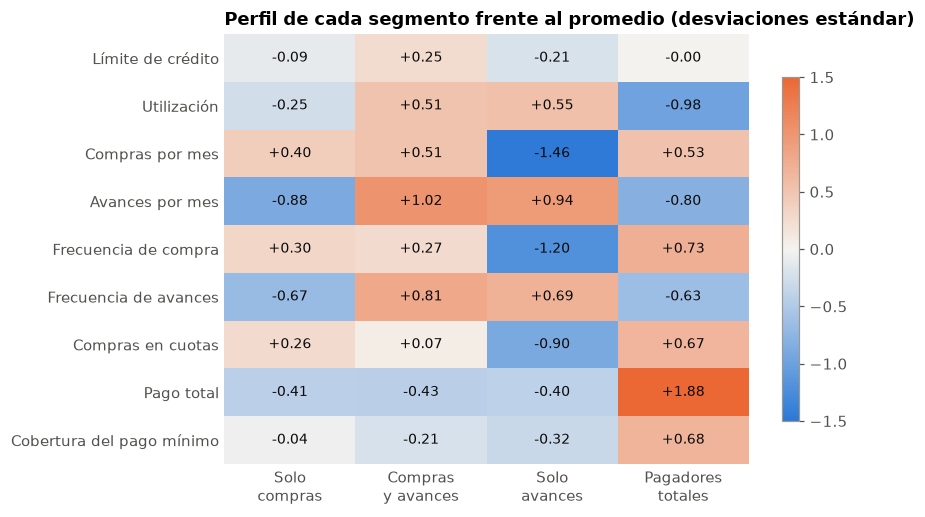

Clientes en frontera (distancia al centro más cercano mayor a 80 % de la distancia al segundo): 10.3 %


In [9]:
dt = df.iloc[te].assign(segmento=segmento.iloc[te].values)
dt['utilizacion'] = (dt['BALANCE'] / dt['CREDIT_LIMIT']).clip(0, 1.5)
VARS_P = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_TRX', 'PRC_FULL_PAYMENT', 'CREDIT_LIMIT', 'PAYMENTS', 'utilizacion', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'TENURE']
tabla_perfil = dt.groupby('segmento')[VARS_P].median().loc[ORDEN].T.round(2)
tabla_perfil.loc['% de clientes'] = (dt['segmento'].value_counts(normalize=True).loc[ORDEN] * 100).round(1).values
display(tabla_perfil)

comp_z = StandardScaler().fit(BASES['comportamiento'].iloc[tr])
Z = pd.DataFrame(comp_z.transform(BASES['comportamiento'].iloc[te]), columns=BASES['comportamiento'].columns)
Z['segmento'] = segmento.iloc[te].values
mapa = Z.groupby('segmento').mean().loc[ORDEN].T
ETIQ = {'log_limite': 'Límite de crédito', 'utilizacion': 'Utilización', 'log_compra_mes': 'Compras por mes', 'log_avance_mes': 'Avances por mes',
        'frec_compra': 'Frecuencia de compra', 'frec_avance': 'Frecuencia de avances', 'pct_cuotas': 'Compras en cuotas', 'pago_total': 'Pago total', 'log_cobertura': 'Cobertura del pago mínimo'}
cmap = LinearSegmentedColormap.from_list('div', [AZUL, '#f4f3ef', NARANJA])
fig, ax = plt.subplots(figsize=(8.2, 4.8))
im = ax.imshow(mapa.values, cmap=cmap, vmin=-1.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(len(ORDEN)), [o.replace(' ', '\n', 1) for o in ORDEN]); ax.set_yticks(range(len(mapa)), [ETIQ[i] for i in mapa.index]); ax.grid(False)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f'{mapa.values[i, j]:+.2f}', ha='center', va='center', color='#0b0b0b', fontsize=9)
ax.set_title('Perfil de cada segmento frente al promedio (desviaciones estándar)')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

distancias = np.sort(np.sqrt(((Xte[:, None, :] - modelo[None, :, :]) ** 2).sum(2)), axis=1) if isinstance(modelo, np.ndarray) else None
if distancias is not None:
    relacion = distancias[:, 0] / distancias[:, 1]
    print(f'Clientes en frontera (distancia al centro más cercano mayor a 80 % de la distancia al segundo): {pct((relacion > 0.8).mean())}')

**Lectura.**

| Segmento | Clientes | Comportamiento |
|---|---|---|
| **Solo compras** | 38.6 % | Compran con frecuencia media, no usan avances y casi nunca pagan el total |
| **Compras y avances** | 23.3 % | Mayor saldo y límite, compran y además retiran efectivo |
| **Solo avances** | 22.3 % | No compran: usan la tarjeta como fuente de efectivo, con utilización de 65 % |
| **Pagadores totales** | 15.8 % | Compran con frecuencia, pagan todo y casi no mantienen saldo |

Cerca del 10.3 % de los clientes está en la frontera entre dos segmentos. Asignarlos con total seguridad sería exagerado, y conviene excluirlos de los pilotos o analizarlos por separado.

## 7. Validación y sensibilidad

### ¿Los segmentos dicen algo sobre variables que no usaron?

Si solo diferenciaran lo que usaron como entrada, serían poco informativos. Por eso miramos eta² variable por variable, y prestamos atención a cuáles de esas variables son realmente independientes.

In [10]:
Xc = comp_z.transform(BASES['comportamiento'])
cols = list(BASES['comportamiento'].columns)
filas = [{'Variable': ETIQ[v], 'Usada para formar segmentos': 'Sí' if (BASE == 'comportamiento' or v in ('log_compra_mes', 'log_avance_mes', 'pago_total')) else 'No',
          'Eta² en prueba': round(eta2(g_crudo[te], te, Xc[:, [cols.index(v)]]), 3)} for v in cols]
display(pd.DataFrame(filas).set_index('Variable').sort_values('Eta² en prueba', ascending=False))

,Usada para formar segmentos,Eta² en prueba
Variable,,
Avances por mes,Sí,0.836
Pago total,Sí,0.792
Compras por mes,Sí,0.684
Frecuencia de avances,No,0.510
Frecuencia de compra,No,0.465
Utilización,No,0.308
Compras en cuotas,No,0.276
Cobertura del pago mínimo,No,0.107
Límite de crédito,No,0.028


**Lectura.** Los segmentos también separan frecuencia de avances (0.510), frecuencia de compra (0.465), utilización (0.308) y uso de cuotas (0.276). **Esta no es una validación independiente:** las dos frecuencias están muy relacionadas con `CASH_ADVANCE` y `PURCHASES`, y la utilización se calcula con `BALANCE`.

Las medidas más alejadas de los datos de entrada se separan mucho menos: cobertura del pago mínimo (0.107) y límite de crédito (0.028). Esta segmentación describe **cómo se usa** la tarjeta, y no la capacidad de crédito del cliente. Una validación real necesitaría datos externos, como rentabilidad, mora o respuesta a campañas.

### ¿Cambia con el azar o con menos datos?

Comparamos con la asignación elegida, sobre los clientes de prueba, usando otras semillas y entrenando con menos clientes.

In [11]:
base_te = g_crudo[te]
agrupado = []
for s_ in range(10):
    agrupado.append(adjusted_rand_score(base_te, asignar(ajustar(ALGORITMO, K_ELEGIDO, X_final[tr], 100 + s_), Xte)))
print(f'Semillas distintas: ARI medio {np.mean(agrupado):.3f} | mínimo {np.min(agrupado):.3f}')

rng = np.random.default_rng(SEMILLA)
filas = []
for frac in [1.0, 0.5, 0.25, 0.10]:
    v = []
    for b in range(10):
        s = rng.choice(len(tr), int(frac * len(tr)), replace=frac == 1.0)
        v.append(adjusted_rand_score(base_te, asignar(ajustar(ALGORITMO, K_ELEGIDO, X_final[tr][s], b), Xte)))
    filas.append({'Parte del entrenamiento': pct(frac, 0), 'Clientes': int(frac * len(tr)), 'ARI medio': round(np.mean(v), 3), 'ARI mínimo': round(np.min(v), 3)})
display(pd.DataFrame(filas).set_index('Parte del entrenamiento'))

Semillas distintas: ARI medio 1.000 | mínimo 1.000


,Clientes,ARI medio,ARI mínimo
Parte del entrenamiento,,,
100 %,5370,0.991,0.987
50 %,2685,0.993,0.983
25 %,1342,0.938,0.502
10 %,537,0.978,0.961


### ¿De qué decisiones depende?

Retiramos cada variable, cambiamos la preparación de datos, y comparamos con otros algoritmos. También entrenamos solo con clientes de 12 meses y aplicamos HDBSCAN, un método que busca regiones densas y puede dejar clientes sin grupo.

In [12]:
B_ = BASES[BASE]
filas = []
for v in B_.columns:
    Xs = StandardScaler().fit(B_.drop(columns=v).iloc[tr]).transform(B_.drop(columns=v))
    g_ = asignar(ajustar(ALGORITMO, K_ELEGIDO, Xs[tr], SEMILLA), Xs[te])
    filas.append({'Variable retirada': v, 'ARI frente al elegido': round(adjusted_rand_score(base_te, g_), 3), 'Eta²': round(eta2(g_, te), 3), 'Cambio de eta²': f'{eta2(g_, te) - eta2(base_te, te):+.3f}'})
display(pd.DataFrame(filas).set_index('Variable retirada'))

def probar(Xn):
    g_ = asignar(ajustar(ALGORITMO, K_ELEGIDO, Xn[tr], SEMILLA), Xn[te])
    return {'ARI frente al elegido': round(adjusted_rand_score(base_te, g_), 3), 'Eta²': round(eta2(g_, te), 3), 'Grupo mínimo': pct(np.bincount(g_, minlength=K_ELEGIDO).min() / len(te))}

crudas = df[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_TRX', 'PRC_FULL_PAYMENT']] if BASE == 'compacta' else BASES[BASE]
lim = B_.iloc[tr].quantile(0.99)
escenarios = {
    'Escala robusta (mediana y rango intercuartílico)': RobustScaler().fit(B_.iloc[tr]).transform(B_),
    'Sin logaritmo': StandardScaler().fit(crudas.iloc[tr]).transform(crudas),
    'Valores extremos limitados al percentil 99': StandardScaler().fit(B_.clip(upper=lim, axis=1).iloc[tr]).transform(B_.clip(upper=lim, axis=1)),
}
display(pd.DataFrame({n: probar(x) for n, x in escenarios.items()}).T)

t12 = np.where(df['TENURE'].iloc[tr].to_numpy() == 12)[0]
g12 = asignar(ajustar(ALGORITMO, K_ELEGIDO, X_final[tr][t12], SEMILLA), Xte)
print(f'Entrenando solo con clientes de 12 meses ({len(t12):,}): ARI {adjusted_rand_score(base_te, g12):.3f}')
bm = base_comportamiento(df, por_mes=False)
print(f'Variables sin dividir por antigüedad (base comportamiento): ARI frente a la versión mensual {adjusted_rand_score(asignar(ajustar("kmeans", K_ELEGIDO, MATRICES["comportamiento"][tr], SEMILLA), MATRICES["comportamiento"][te]), asignar(ajustar("kmeans", K_ELEGIDO, StandardScaler().fit(bm.iloc[tr]).transform(bm)[tr], SEMILLA), StandardScaler().fit(bm.iloc[tr]).transform(bm)[te])):.3f}')

ward = asignar(ajustar('ward', K_ELEGIDO, X_final[tr], SEMILLA), Xte)
gmm = asignar(ajustar('gmm', K_ELEGIDO, X_final[tr], SEMILLA), Xte)
print(f'Coincidencia con otros algoritmos (ARI): Ward {adjusted_rand_score(base_te, ward):.3f} | Mezcla gaussiana {adjusted_rand_score(base_te, gmm):.3f}')
dens = HDBSCAN(min_cluster_size=100).fit_predict(X_final[tr])
print(f'HDBSCAN: {len(set(dens) - {-1})} grupos densos | {pct((dens == -1).mean())} de clientes clasificados como ruido')

,ARI frente al elegido,Eta²,Cambio de eta²
Variable retirada,,,
BALANCE,0.939,0.461,-0.002
PURCHASES,0.442,0.430,-0.033
CASH_ADVANCE,0.485,0.404,-0.059
PURCHASES_TRX,0.970,0.462,-0.001
PRC_FULL_PAYMENT,0.623,0.399,-0.064


,ARI frente al elegido,Eta²,Grupo mínimo
Escala robusta (mediana y rango intercuartílico),0.515,0.408,14.4 %
Sin logaritmo,0.236,0.282,4.2 %
Valores extremos limitados al percentil 99,1.0,0.463,15.8 %


Entrenando solo con clientes de 12 meses (4,544): ARI 0.985
Variables sin dividir por antigüedad (base comportamiento): ARI frente a la versión mensual 0.912


Coincidencia con otros algoritmos (ARI): Ward 0.980 | Mezcla gaussiana 0.713


HDBSCAN: 3 grupos densos | 17.1 % de clientes clasificados como ruido


**Lectura.**

- **Azar.** Con otras semillas, la asignación no cambia (ARI de 1.000).
- **Menos datos.** Se mantiene con el 50 % y el 10 % de los clientes. Con 25 %, una corrida cayó a 0.502, así que muestras pequeñas pueden dar soluciones distintas.
- **Variables.** `PURCHASES`, `CASH_ADVANCE` y `PRC_FULL_PAYMENT` definen la estructura. Sin `BALANCE` o `PURCHASES_TRX` casi nada cambia, y por eso son candidatas a retirarse en una versión más simple.
- **Preparación.** **Es la mayor fragilidad.** Con escala robusta, el ARI cae a 0.515, y sin logaritmo, a 0.236. La segmentación depende de cómo se transforman los datos, así que esa decisión debe documentarse y mantenerse.
- **Otros algoritmos.** Ward coincide casi por completo (0.980), y la mezcla gaussiana en menor medida (0.713).
- **Antigüedad.** Entrenar solo con clientes de 12 meses casi no cambia el resultado (0.985).
- **Densidad.** HDBSCAN encuentra 3 grupos y deja 17.1 % sin asignar. Los clientes sí forman aglomeraciones, en buena parte por los ceros en compras y avances.

## 8. Uso en la gestión

### De modelo a reglas

Un árbol de decisión de profundidad 2 imita al modelo. **Fidelidad** es el porcentaje de clientes de prueba que las reglas asignan al mismo segmento.

### Dimensionar el piloto

Pertenecer a un segmento no demuestra que una oferta funcione. Para saberlo se necesita un **grupo de control aleatorio**. Si la mitad de cada segmento recibe la acción, el **efecto mínimo detectable** es:

$$(z_{\alpha} + z_{\beta}) \sqrt{\frac{2\,p(1-p)}{n}}$$

Donde $p$ es la respuesta base, un valor ilustrativo de 5 %, y $n$ es el número de clientes por grupo. Indica qué diferencia se podría distinguir del azar con 95 % de confianza y 80 % de potencia.

In [13]:
CANDIDATAS_REGLA = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PURCHASES_TRX', 'PRC_FULL_PAYMENT'] if BASE == 'compacta' else list(BASES[BASE].columns)
datos_regla = df if BASE == 'compacta' else BASES[BASE]
arbol = DecisionTreeClassifier(max_depth=2, min_samples_leaf=50, random_state=SEMILLA).fit(datos_regla[CANDIDATAS_REGLA].iloc[tr], segmento.iloc[tr])
fidelidad = (arbol.predict(datos_regla[CANDIDATAS_REGLA].iloc[te]) == segmento.iloc[te].to_numpy()).mean()
print(f'Coincidencia entre las reglas y el modelo en prueba: {pct(fidelidad)}\n')
print(export_text(arbol, feature_names=CANDIDATAS_REGLA, decimals=1))

conteo = segmento.value_counts().loc[ORDEN]
z_total = Z_ALFA + Z_POTENCIA
filas = []
for nom, n_seg in conteo.items():
    por_brazo = n_seg // 2
    mde = z_total * np.sqrt(2 * RESPUESTA_BASE * (1 - RESPUESTA_BASE) / por_brazo)
    filas.append({'Segmento': nom, 'Clientes': int(n_seg), 'Por grupo (tratamiento y control)': por_brazo, 'Efecto mínimo detectable': f'{100 * mde:.1f} puntos'})
display(pd.DataFrame(filas).set_index('Segmento'))

Coincidencia entre las reglas y el modelo en prueba: 96.9 %

|--- CASH_ADVANCE <= 18.5
|   |--- PRC_FULL_PAYMENT <= 0.3
|   |   |--- class: Solo compras
|   |--- PRC_FULL_PAYMENT >  0.3
|   |   |--- class: Pagadores totales
|--- CASH_ADVANCE >  18.5
|   |--- PURCHASES <= 66.2
|   |   |--- class: Solo avances
|   |--- PURCHASES >  66.2
|   |   |--- class: Compras y avances



,Clientes,Por grupo (tratamiento y control),Efecto mínimo detectable
Segmento,,,
Solo compras,3281,1640,2.1 puntos
Compras y avances,2004,1002,2.7 puntos
Solo avances,2163,1081,2.6 puntos
Pagadores totales,1502,751,3.1 puntos


**Lectura.** Las reglas coinciden con el modelo en 96.9 % de los clientes de prueba:

| Si... | Segmento | Hipótesis para el piloto |
|---|---|---|
| `CASH_ADVANCE` ≤ 18.5 y `PRC_FULL_PAYMENT` ≤ 0.3 | Solo compras | Promover compras en cuotas o productos complementarios |
| `CASH_ADVANCE` ≤ 18.5 y `PRC_FULL_PAYMENT` > 0.3 | Pagadores totales | Beneficios por uso para fidelizar |
| `CASH_ADVANCE` > 18.5 y `PURCHASES` ≤ 66.2 | Solo avances | Activar compras u ofrecer una alternativa de liquidez más barata |
| `CASH_ADVANCE` > 18.5 y `PURCHASES` > 66.2 | Compras y avances | Revisión de riesgo y educación financiera antes de cualquier oferta |

Estas acciones son **hipótesis por probar**. Con segmentos que usan mucho efectivo, una oferta mal diseñada puede empeorar el endeudamiento del cliente, y requiere revisión de riesgos.

Con esta base solo podrían detectarse efectos de 2.1 a 3.1 puntos. Si se espera un efecto menor, hace falta una base mayor o un piloto más largo.

## 9. Ficha del modelo

Reúne en un solo lugar qué hace la segmentación, con qué datos se construyó y qué tan bien funciona.

In [14]:
ficha = {
    'Segmentación': f'{ALGORITMO}, base {BASE}, {K_ELEGIDO} segmentos',
    'Variables': ', '.join(BASES[BASE].columns),
    'Preparación': 'log(1 + x) y estandarización ajustada en entrenamiento',
    'Clientes': f'{len(tr):,} entrenamiento, {len(va):,} validación, {len(te):,} prueba',
    'Eta² en prueba': f'{eta2(g_crudo[te], te):.3f}',
    'Silhouette en prueba (datos sin estructura)': f'{silhouette_score(Xte, g_crudo[te]):.3f} ({np.mean(nulo_te):.3f})',
    'ARI entre reentrenamientos (validación, percentil 10)': f'{cand.iloc[0]["ari_p10"]:.3f}',
    'Coincidencia de las reglas': pct(fidelidad),
}
display(pd.DataFrame({'Valor': ficha}))

,Valor
Segmentación,"kmeans, base compacta, 4 segmentos"
Variables,"BALANCE, PURCHASES, CASH_ADVANCE, PURCHASES_TR..."
Preparación,log(1 + x) y estandarización ajustada en entre...
Clientes,"5,370 entrenamiento, 1,790 validación, 1,790 p..."
Eta² en prueba,0.463
Silhouette en prueba (datos sin estructura),0.416 (0.252)
"ARI entre reentrenamientos (validación, percentil 10)",0.983
Coincidencia de las reglas,96.9 %


**Diccionario de las variables utilizadas**

| Variable | Definición | Tratamiento |
|---|---|---|
| `BALANCE` | Saldo adeudado en la tarjeta (supuesto) | `log(1 + x)` y estandarización |
| `PURCHASES` | Monto de compras | `log(1 + x)` y estandarización |
| `CASH_ADVANCE` | Efectivo adelantado | `log(1 + x)` y estandarización |
| `PURCHASES_TRX` | Número de compras | `log(1 + x)` y estandarización |
| `PRC_FULL_PAYMENT` | Proporción de pagos totales realizados | `log(1 + x)` y estandarización |

Las definiciones provienen de la descripción del conjunto de datos, que no indica moneda.

**Supuesto sobre `BALANCE`.** La descripción lo define como el saldo que queda en la cuenta para hacer compras, lo que sugiere un monto disponible. Aquí lo interpretamos como **saldo adeudado** por dos razones: los pagadores totales tienen el saldo más bajo (mediana de 68), y 227 clientes tienen un valor mayor que su límite, algo imposible para un monto disponible. Si fuera saldo disponible, habría que invertir la lectura de la utilización.

## 10. Limitaciones y monitoreo

**Limitaciones**

- **Sin tiempo.** Hay una sola foto de cada cliente, así que no se puede saber si los segmentos persisten ni si los clientes migran.
- **Sin resultado de negocio.** No hay datos de rentabilidad, mora o respuesta a campañas, por lo que no se puede afirmar qué segmento vale más.
- **Sin variables demográficas.** No se puede evaluar si la segmentación afecta de forma desigual a ciertos grupos.
- **Dependencia de la preparación.** Cambiar la escala o el logaritmo modifica la segmentación.
- **Periodo ambiguo.** La descripción habla de 6 meses y `TENURE` llega a 12.
- **Significado de `BALANCE`.** Se interpreta como saldo adeudado, aunque la descripción del archivo sugiere otra cosa.
- **Diseño no totalmente ciego.** La regla de decisión se definió después de ver los resultados de validación. Tras ver la prueba solo se corrigieron los nombres de los segmentos y se simplificó el árbol de reglas.
- **Las acciones no fueron probadas.** Son hipótesis para un piloto.

**Plan de monitoreo propuesto**

| Indicador | Frecuencia | Verde | Revisar | Actuar |
|---|---|---|---|---|
| PSI de la distribución de segmentos | Mensual | ≤ 0.10 | 0.10 a 0.25 | > 0.25 |
| Tamaño del segmento más pequeño | Mensual | ≥ 10 % | 8 % a 10 % | < 8 % |
| ARI al reentrenar con datos recientes | Trimestral | ≥ 0.80 | 0.60 a 0.80 | < 0.60 |
| Clientes que cambian de segmento | Trimestral | Definir con el primer histórico | | |

Son una propuesta inicial, y deben ajustarse con datos reales.

## Conclusión

**Hay cuatro segmentos útiles.** Son estables y tienen tamaños accionables. Su valor comercial todavía debe confirmarse con datos externos y con un piloto.

| Segmento | Clientes | Primera hipótesis por probar |
|---|---|---|
| Solo compras | 38.6 % | Compras en cuotas o productos complementarios |
| Compras y avances | 23.3 % | Revisión de riesgo y educación financiera |
| Solo avances | 22.3 % | Activar compras o una alternativa de liquidez |
| Pagadores totales | 15.8 % | Beneficios para fidelizar |

**Recomendación.** Operar con las cuatro reglas de la sección 8, que coinciden con el modelo en 96.9 % de los casos y se pueden explicar sin matemáticas. Usar k-means para revisar periódicamente si la estructura sigue vigente, y medir el efecto de cada acción con un grupo de control.

**Las ideas para llevarse**

1. En segmentación no hay una respuesta correcta: hay criterios que se declaran y se defienden.
2. Una sola métrica puede llevar a una mala decisión: por eso se combinan tamaño, estabilidad e información resumida.
3. Compara siempre contra datos sin estructura y contra una regla simple.
4. Un modelo también es valioso cuando confirma que una regla simple es suficiente.
5. Un segmento describe a un cliente. No demuestra que una acción vaya a funcionar.

## Ejercicios

1. **Cambia `K_MINIMO` a 2.** ¿Se mantiene la elección? ¿Por qué?
2. **Cambia `GANANCIA_MINIMA` a 0.01.** ¿Cuántos segmentos se eligen? ¿Podrías diseñar una acción para cada uno?
3. **Sube `TAMANO_MINIMO` a 0.20.** ¿Qué configuraciones sobreviven?
4. **Modifica la regla de actividad** con otro umbral de pago total. ¿Cambia su eta²?
5. **Retira `BALANCE` y `PURCHASES_TRX` de `base_compacta`.** ¿Vale la pena conservarlas?
6. **Para pensar:** si un segmento usa muchos avances, ¿ofrecerle más crédito beneficia al banco y al cliente?